# Clasificación de reseñas hoteleras

**Proyectos de Machine Learning · CENESTUR**  
**Integrantes:** Bryan Velastegui y Evelyn Morocho

El problema consiste en clasificar el texto de una reseña como **negativa (0)** o **positiva (1)** para apoyar la revisión de comentarios de huéspedes. El cuaderno reproduce el flujo de la materia: adquirir datos reales, limpiarlos, separar conjuntos por grupos, entrenar, ajustar parámetros, medir el desempeño y guardar el pipeline que utiliza la API.

Se usa [Andalusian Hotels’ Reviews v3](https://www.kaggle.com/datasets/chizhikchi/andalusian-hotels-reviews-unbalanced/versions/3), publicado por Mariia Chizhikova en Kaggle con licencia declarada CC BY-NC 4.0. Las estrellas son una aproximación al sentimiento.

## 1. Entorno y parámetros

Ejecutar de arriba abajo desde la carpeta del proyecto con las dependencias de `requirements.txt`. Para explorar cambios en la rejilla, dejar `EVALUAR_PRUEBA = False`. Los valores incluidos reproducen el experimento de la aplicación.

In [1]:
import csv
import hashlib
import io
import json
import re
import shutil
import tempfile
import unicodedata
from collections import Counter, defaultdict
from importlib.metadata import version
from pathlib import Path
from statistics import mean, stdev

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import ParameterGrid, StratifiedGroupKFold
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

BASE = Path.cwd()
DATOS = BASE / "datos"
RESULTADOS = BASE / "resultados"
SOURCE = DATOS / "Big_AHR.csv"
DATASET = "chizhikchi/andalusian-hotels-reviews-unbalanced/3"
SHA256_ORIGINAL = "1eac75de3099cee4d7b688444511a1e26b24c225922518d22410351d1cdf5c39"
SEMILLA = 42
C_LOGISTICA = [0.5, 1.0, 2.0]
ALPHA_NAIVE_BAYES = [0.5, 1.0, 2.0]
EVALUAR_PRUEBA = True
EXPORTAR_MODELO = True
DESTINO_MODELO = RESULTADOS / "modelo"
DESTINO_FIGURAS = RESULTADOS / "figuras_modelo"

for carpeta in (DATOS, RESULTADOS, DESTINO_FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
AZUL = "#234c7c"
TURQUESA = "#0f766e"
NARANJA = "#b9572b"
GRIS = "#687788"


def escribir_json(ruta, datos):
    ruta.write_text(json.dumps(datos, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")


def sha256(ruta):
    return hashlib.sha256(ruta.read_bytes()).hexdigest()


def huella_csv(filas):
    memoria = io.StringIO(newline="")
    escritor = csv.DictWriter(memoria, fieldnames=list(filas[0]))
    escritor.writeheader()
    escritor.writerows(filas)
    return hashlib.sha256(memoria.getvalue().encode("utf-8")).hexdigest()


def mostrar_figura(figura, nombre):
    figura.tight_layout()
    figura.savefig(DESTINO_FIGURAS / f"{nombre}.png", dpi=220, bbox_inches="tight")
    plt.show()
    plt.close(figura)

## 2. Obtener y comprobar el corpus

Se reutiliza `datos/Big_AHR.csv` si su huella coincide con la versión auditada. Cuando el archivo falta, el cliente oficial de Kaggle descarga la versión 3 con las credenciales locales. Se copia únicamente `Big_AHR.csv`. El archivo balanceado comparte textos con el corpus completo y sus positivos se concentran en cinco estrellas.

In [2]:
if not SOURCE.exists() or sha256(SOURCE) != SHA256_ORIGINAL:
    from kaggle.api.kaggle_api_extended import KaggleApi

    api = KaggleApi()
    api.authenticate()
    with tempfile.TemporaryDirectory(prefix="ahr_kaggle_") as directorio:
        api.dataset_download_files(DATASET, path=directorio, unzip=True, quiet=True)
        descargado = Path(directorio) / SOURCE.name
        if sha256(descargado) != SHA256_ORIGINAL:
            raise ValueError("La huella del archivo descargado difiere de la versión auditada")
        shutil.copyfile(descargado, SOURCE)
    escribir_json(DATOS / "descarga_oficial.json", {
        "dataset": DATASET, "cliente": "kaggle", "version_cliente": version("kaggle"),
        "archivo": SOURCE.name, "sha256": sha256(SOURCE),
    })
    print("Corpus descargado con Kaggle y verificado.")
else:
    print("Archivo local verificado contra el SHA-256 de AHR v3.")

with SOURCE.open(encoding="utf-8-sig", newline="") as archivo:
    originales = list(csv.DictReader(archivo))
print(f"Filas originales: {len(originales):,}")

Archivo local verificado contra el SHA-256 de AHR v3.
Filas originales: 18,172


## 3. Limpiar, etiquetar y explorar

Las valoraciones de 1 y 2 estrellas son negativas y las de 4 y 5 son positivas. Se excluyen las de 3 estrellas. Unicode, espacios y mayúsculas se normalizan solo para agrupar duplicados. Se conserva el texto de la primera fila de cada grupo y se verifica la trazabilidad a todas las filas de origen. Solo `review_text` entra al pipeline.

In [3]:
def normalizar(texto):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", texto)).strip().casefold()


def preparar(filas):
    grupos = {}
    descartadas = Counter()
    for numero, fila in enumerate(filas, start=2):
        rating = int(fila["rating"])
        esperado = {1: "0", 2: "0", 3: "3", 4: "1", 5: "1"}[rating]
        if fila["label"] != esperado:
            raise ValueError(f"Etiqueta incompatible con estrellas en fila {numero}")
        if rating == 3:
            descartadas["tres_estrellas"] += 1
            continue
        texto = normalizar(fila["review_text"])
        if not texto:
            raise ValueError(f"Texto vacío en fila {numero}")
        grupo = grupos.setdefault(texto, [])
        grupo.append((numero, fila))

    registros = []
    for texto, grupo in grupos.items():
        etiquetas = {fila["label"] for _, fila in grupo}
        if len(etiquetas) != 1:
            raise ValueError("Un mismo texto tiene etiquetas contradictorias")
        primera = grupo[0][1]
        hoteles = sorted({fila["hotel"].strip() for _, fila in grupo if fila["hotel"].strip()})
        registros.append({
            "id": hashlib.sha256(texto.encode()).hexdigest(),
            "title": primera["title"].strip(),
            "review_text": primera["review_text"].strip(),
            "label": primera["label"],
            "sentimiento": "positivo" if primera["label"] == "1" else "negativo",
            "hoteles_json": json.dumps(hoteles, ensure_ascii=False),
            "filas_originales_json": json.dumps([numero for numero, _ in grupo]),
        })
    registros.sort(key=lambda registro: registro["id"])
    return registros, {
        "fuente": DATASET,
        "licencia_declarada": "CC BY-NC 4.0",
        "sha256_original": sha256(SOURCE),
        "sha256_procesado": huella_csv(registros),
        "filas_originales": len(filas),
        "excluidas_tres_estrellas": descartadas["tres_estrellas"],
        "duplicados_binarios_excedentes": sum(len(grupo) - 1 for grupo in grupos.values()),
        "textos_binarios_unicos": len(registros),
        "clases": dict(Counter(fila["sentimiento"] for fila in registros)),
    }


def verificar_limpieza(filas, originales, resumen):
    assert filas, "El conjunto está vacío"
    assert {r["label"] for r in filas} == {"0", "1"}, "Etiquetas no binarias"
    assert len({normalizar(r["review_text"]) for r in filas}) == len(filas), "Textos repetidos"
    assert all(r["review_text"].strip() for r in filas), "Hay textos vacíos"
    fuentes = set()
    for fila in filas:
        texto = normalizar(fila["review_text"])
        assert fila["id"] == hashlib.sha256(texto.encode()).hexdigest(), "ID incompatible"
        assert fila["sentimiento"] == ("positivo" if fila["label"] == "1" else "negativo")
        indices = json.loads(fila["filas_originales_json"])
        assert indices, "Falta trazabilidad"
        for indice in indices:
            assert indice not in fuentes, "Fila original contada dos veces"
            fuentes.add(indice)
            original = originales[indice - 2]
            assert normalizar(original["review_text"]) == texto
            assert original["label"] == fila["label"]
            assert int(original["rating"]) != 3
    esperadas = {i for i, r in enumerate(originales, 2) if int(r["rating"]) != 3}
    assert fuentes == esperadas, "Faltan o sobran filas originales binarias"
    assert resumen["textos_binarios_unicos"] == len(filas)
    assert resumen["clases"] == dict(Counter(r["sentimiento"] for r in filas))

resenas, preparacion = preparar(originales)
verificar_limpieza(resenas, originales, preparacion)
escribir_json(DATOS / "preparacion.json", preparacion)
display(pd.DataFrame({"Etapa": ["Reseñas originales", "Excluidas por tres estrellas",
    "Filas duplicadas retiradas", "Reseñas binarias únicas"], "Cantidad": [
    preparacion["filas_originales"], preparacion["excluidas_tres_estrellas"],
    preparacion["duplicados_binarios_excedentes"], preparacion["textos_binarios_unicos"]]}))

,Etapa,Cantidad
0,Reseñas originales,18172
1,Excluidas por tres estrellas,2274
2,Filas duplicadas retiradas,4308
3,Reseñas binarias únicas,11590


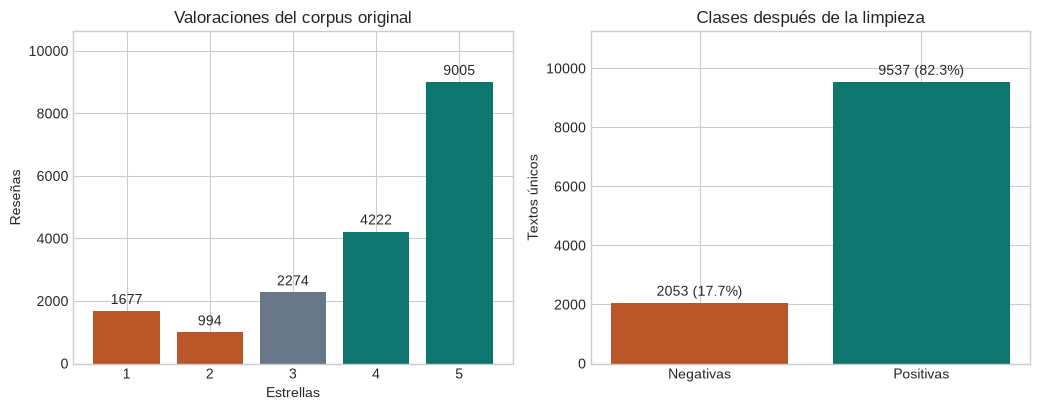

In [4]:
estrellas = Counter(int(fila["rating"]) for fila in originales)
clases = Counter(int(fila["label"]) for fila in resenas)
fig, ejes = plt.subplots(1, 2, figsize=(10.5, 4.2))
barras = ejes[0].bar(range(1, 6), [estrellas[i] for i in range(1, 6)],
                    color=[NARANJA, NARANJA, GRIS, TURQUESA, TURQUESA])
ejes[0].bar_label(barras, padding=3)
ejes[0].set(title="Valoraciones del corpus original", xlabel="Estrellas", ylabel="Reseñas", ylim=(0, max(estrellas.values()) * 1.18))
ejes[0].set_xticks(range(1, 6))
barras = ejes[1].bar(["Negativas", "Positivas"], [clases[0], clases[1]], color=[NARANJA, TURQUESA])
ejes[1].bar_label(barras, [f"{clases[i]} ({clases[i]/len(resenas):.1%})" for i in (0, 1)], padding=3)
ejes[1].set(title="Clases después de la limpieza", ylabel="Textos únicos", ylim=(0, max(clases.values()) * 1.18))
mostrar_figura(fig, "01_distribucion_del_corpus")

## 4. Crear las particiones por grupos

Se conectan reseñas del mismo hotel conocido y textos que coinciden al quitar espacios y puntuación. A partir de cinco pliegues estratificados por grupos, se fijan tres para **entrenamiento**, uno para **validación** y uno para **prueba**. Estos conjuntos fijos cumplen funciones distintas. No se equilibran por submuestreo y se comprueba la separación de grupos, hoteles y coincidencias de texto. Los hoteles sin identificador solo se pueden agrupar por coincidencia de texto.

In [5]:
def preparar_particiones(filas):
    padres = list(range(len(filas)))

    def raiz(i):
        while padres[i] != i:
            padres[i] = padres[padres[i]]
            i = padres[i]
        return i

    def unir(a, b):
        a, b = raiz(a), raiz(b)
        padres[max(a, b)] = min(a, b)

    hoteles, textos = {}, {}
    for i, fila in enumerate(filas):
        for hotel in json.loads(fila["hoteles_json"]):
            clave = normalizar(hotel)
            if clave in hoteles:
                unir(i, hoteles[clave])
            hoteles[clave] = i
        # Une también variaciones que solo cambian puntuación o espacios.
        # No se declara detección exhaustiva de paráfrasis o duplicados cercanos.
        texto = re.sub(r"[\W_]+", "", normalizar(fila["review_text"]))
        if texto in textos:
            unir(i, textos[texto])
        textos[texto] = i
    grupos = np.array([raiz(i) for i in range(len(filas))])
    y = np.array([int(fila["label"]) for fila in filas])
    asignaciones = np.empty(len(filas), dtype=int)
    divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    for fold, (_, indices) in enumerate(divisor.split(np.zeros(len(y)), y, grupos)):
        asignaciones[indices] = fold
    nombres = {0: "prueba", 1: "validacion", 2: "entrenamiento", 3: "entrenamiento", 4: "entrenamiento"}
    registros = [{"id": f["id"], "grupo": str(grupos[i]), "particion": nombres[asignaciones[i]]}
                 for i, f in enumerate(filas)]
    for nombre in set(nombres.values()):
        indices = [i for i, r in enumerate(registros) if r["particion"] == nombre]
        if set(y[indices]) != {0, 1}:
            raise ValueError(f"La partición {nombre} no contiene ambas clases")
    destinos = {raiz(i): set() for i in range(len(filas))}
    for i, r in enumerate(registros):
        destinos[raiz(i)].add(r["particion"])
    assert all(len(v) == 1 for v in destinos.values())
    resumen = {
        "semilla": SEMILLA,
        "metodo": "StratifiedGroupKFold de 5 folds; fold 0 prueba, 1 validación, 2–4 entrenamiento",
        "sha256_dataset": huella_csv(filas),
        "sha256_particiones": huella_csv(registros),
        "grupos": len(set(grupos.tolist())),
        "grupo_mayor": max(Counter(grupos.tolist()).values()),
        "regla_grupos": "Componentes conexas por hotel y por texto sin puntuación ni espacios; sin hotel queda agrupado solo por coincidencias de texto",
        "limitacion": "Los hoteles ausentes no permiten garantizar separación por establecimiento; no se detectan todas las paráfrasis",
        "balance": "No se submuestrea ni duplica ninguna partición; usar pesos calculados solo con entrenamiento",
        "particiones": {},
    }
    for nombre in ["entrenamiento", "validacion", "prueba"]:
        indices = [i for i, r in enumerate(registros) if r["particion"] == nombre]
        resumen["particiones"][nombre] = {
            "total": len(indices), "negativas": int(sum(y[indices] == 0)),
            "positivas": int(sum(y[indices] == 1)),
        }
    return registros, resumen


def verificar_particiones(filas, partes, resumen):
    por_id = {r["id"]: r["particion"] for r in partes}
    assert len(por_id) == len(partes) == len(filas)
    assert set(por_id) == {r["id"] for r in filas}
    assert set(por_id.values()) == {"entrenamiento", "validacion", "prueba"}
    hoteles, textos, grupos = defaultdict(set), defaultdict(set), defaultdict(set)
    for r in filas:
        nombre = por_id[r["id"]]
        for hotel in json.loads(r["hoteles_json"]):
            hoteles[normalizar(hotel)].add(nombre)
        textos[re.sub(r"[\W_]+", "", normalizar(r["review_text"]))].add(nombre)
    for r in partes:
        grupos[r["grupo"]].add(r["particion"])
    for categoria in [hoteles, textos, grupos]:
        assert all(len(particiones) == 1 for particiones in categoria.values())
    for nombre, conteo in resumen["particiones"].items():
        seleccion = [r for r in filas if por_id[r["id"]] == nombre]
        assert len(seleccion) == conteo["total"]
        assert sum(r["label"] == "0" for r in seleccion) == conteo["negativas"]
        assert sum(r["label"] == "1" for r in seleccion) == conteo["positivas"]

asignaciones, particiones = preparar_particiones(resenas)
verificar_particiones(resenas, asignaciones, particiones)
escribir_json(DATOS / "particiones.json", particiones)
por_id = {fila["id"]: fila for fila in asignaciones}
conjuntos = {nombre: [] for nombre in particiones["particiones"]}
for fila in resenas:
    conjuntos[por_id[fila["id"]]["particion"]].append(fila)

display(pd.DataFrame(particiones["particiones"]).T)

,total,negativas,positivas
entrenamiento,6949,1229,5720
validacion,2324,414,1910
prueba,2317,410,1907
